# 5. Estacionariedad, memoria y varianza

El análisis numérico utiliza el periodo completo de desarrollo **2000–2021**. Los ajustes de escaladores y modelos se realizan dentro de cada fold.

ADF contrasta una raíz unitaria; KPSS contrasta estacionariedad alrededor de una constante. Se usan de forma conjunta y con las cuatro interpretaciones posibles. Las pruebas se ejecutan sobre medias diarias para separar el diagnóstico de cambios lentos del ciclo intradiario. Su interpretación se circunscribe a la frecuencia diaria analizada.

ADF selecciona por AIC hasta 30 rezagos y KPSS usa rezagos automáticos. Se informan los límites de los p-valores tabulados de KPSS. ACF/PACF se calculan sobre log1p horario, con bandas aproximadas que no representan pruebas independientes para cientos de rezagos. ARCH y Ljung–Box usan residuos de un AR(7) de diagnóstico ajustado en desarrollo; BDS usa sus últimos mil residuos. El AR(7) se utiliza como modelo auxiliar para el diagnóstico de residuos.

Documentación primaria: [ADF](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.adfuller.html), [KPSS](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.kpss.html), [BDS](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.bds.html).


In [1]:
%matplotlib inline
from pathlib import Path

ROOT = next(
    directory for directory in [Path.cwd(), *Path.cwd().parents]
    if (directory / "data/manifest.json").exists()
)

from statsmodels.tsa.ar_model import AutoReg
from IPython.display import Markdown, display
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf, bds
from statsmodels.stats.diagnostic import het_arch, acorr_ljungbox
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

In [2]:
TARGET = 'precio_bolsa_cop_kwh'
EDA_SPLITS = {'train': (2000, 2017), 'validation': (2018, 2021), 'test': (2022, 2025)}
SPLITS = EDA_SPLITS
TIME = 'timestamp_start_colombia'
RESULTS = ROOT / 'results'
PIPELINE_DEFAULTS = {'method': 'split_train_val_forwardChaining', 'n_splits': 5, 'development_start': '2000-01-01T00:00:00-05:00', 'validation_start': '2018-01-01T00:00:00-05:00', 'development_end_exclusive': '2022-01-01T00:00:00-05:00', 'test_start': '2022-01-01T00:00:00-05:00', 'test_end_exclusive': '2026-01-01T00:00:00-05:00', 'lookback_hours': 168, 'horizon_hours': 24, 'stride_hours': 24, 'hourly_release_lag_hours': 24, 'hydrology_release_lag_days': 2, 'include_calendar': True, 'seed': 11037, 'availability_scenario': 'retrospective_assumed_release_lags'}
RESULTS.mkdir(exist_ok=True)
(RESULTS / 'figures').mkdir(exist_ok=True)
(RESULTS / 'tables').mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (11, 4.4), 'figure.dpi': 110, 'savefig.dpi': 160, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.18, 'axes.prop_cycle': plt.cycler(color=['#245b8d', '#d17a32', '#2b8c77', '#8c5da8', '#9a4949'])})
pd.set_option('display.max_rows', 35)
pd.set_option('display.max_columns', 14)
pd.set_option('display.float_format', lambda x: f'{x:.5g}')

In [3]:
def decision(preprocess, architecture, validation, risk):
    display(Markdown('### Implicaciones del análisis\n\n' + '\n'.join(('- **' + a + ':** ' + b for a, b in [('Preprocesamiento', preprocess), ('Arquitectura', architecture), ('Validación', validation), ('Riesgos', risk)]))))

In [4]:
def table(frame, name):
    frame.to_csv(RESULTS / 'tables' / (name + '.csv'), index=True)
    display(frame)
    return None

In [5]:
def load_numeric(split='train', table='hourly', *, allow_test=False):
    if split not in SPLITS:
        raise ValueError('Unknown split')
    if split == 'test' and (not allow_test):
        raise PermissionError('El EDA no puede consultar valores de prueba.')
    a, b = SPLITS[split]
    folder = 'hourly' if table == 'hourly' else 'hydrology'
    frame = pd.concat([pd.read_csv(ROOT / f'data/numeric/{folder}/{year}.csv.gz') for year in range(a, b + 1)], ignore_index=True)
    if table == 'hourly':
        frame.index = pd.DatetimeIndex(pd.to_datetime(frame[TIME], utc=True)).tz_convert('America/Bogota')
    else:
        frame.index = pd.DatetimeIndex(pd.to_datetime(frame['date'])).tz_localize('America/Bogota')
    frame.index.name = 'tiempo_colombia'
    return frame

In [6]:
def load_development_data(table='hourly'):
    return pd.concat([load_numeric('train', table=table), load_numeric('validation', table=table)]).sort_index()

In [7]:
def pipeline_config(overrides=None):
    config = dict(PIPELINE_DEFAULTS)
    if overrides:
        unknown = set(overrides) - set(config)
        if unknown:
            raise ValueError('Opciones desconocidas: ' + str(sorted(unknown)))
        config.update(overrides)
    for field in ['n_splits', 'lookback_hours', 'horizon_hours', 'stride_hours']:
        if not isinstance(config[field], int) or isinstance(config[field], bool) or config[field] < 1:
            raise ValueError('Se requiere un entero positivo: ' + field)
    for field in ['hourly_release_lag_hours', 'hydrology_release_lag_days']:
        if not isinstance(config[field], int) or isinstance(config[field], bool) or config[field] < 0:
            raise ValueError('Rezago inválido: ' + field)
    if config['hydrology_release_lag_days'] < 1:
        raise ValueError('La hidrología diaria requiere al menos el cierre del día.')
    for field in ['development_start', 'validation_start', 'development_end_exclusive', 'test_start', 'test_end_exclusive']:
        if pd.Timestamp(config[field]).tzinfo is None:
            raise ValueError('Se requiere zona horaria: ' + field)
    if config['method'] != 'split_train_val_forwardChaining':
        raise ValueError('Método no autorizado')
    if pd.Timestamp(config['test_start']) != pd.Timestamp(PIPELINE_DEFAULTS['test_start']) or config['test_end_exclusive'] != PIPELINE_DEFAULTS['test_end_exclusive']:
        raise ValueError('El periodo de prueba está congelado.')
    if not pd.Timestamp(config['development_start']) < pd.Timestamp(config['validation_start']) < pd.Timestamp(config['development_end_exclusive']) <= pd.Timestamp(config['test_start']):
        raise ValueError('Cortes temporales inválidos')
    if config['stride_hours'] % 24:
        raise ValueError('Los orígenes deben conservar el paso diario.')
    return config

In [8]:
def load_pipeline_config(path=None):
    path = ROOT / 'configs/training_pipeline.json' if path is None else path
    return pipeline_config(json.loads(path.read_text(encoding='utf-8')))

In [9]:
def load_eda_development(table='hourly'):
    """Desarrollo completo; no cambia las particiones que usa el entrenamiento."""
    config = load_pipeline_config()
    frame = load_development_data(table)
    if len(frame) and frame.index.max() >= pd.Timestamp(config['test_start']):
        raise PermissionError('La fuente contiene fechas de prueba.')
    start = pd.Timestamp(config['development_start'])
    end = pd.Timestamp(config['development_end_exclusive'])
    frame = frame.loc[(frame.index >= start) & (frame.index < end)]
    if frame.empty or frame.index.max() >= pd.Timestamp(config['test_start']):
        raise PermissionError('El EDA sólo admite desarrollo anterior a prueba.')
    return frame

In [10]:
def development_daily():
    frame = load_eda_development()
    return (frame, frame[TARGET].resample('D').mean())

In [11]:
def figure(fig, name):
    fig.tight_layout()
    fig.savefig(RESULTS / 'figures' / (name + '.png'), bbox_inches='tight')
    plt.show()
    plt.close(fig)

In [12]:
frame, daily = development_daily()
rows = []
candidates = {'nivel_diario': daily, 'log1p_diario': np.log1p(daily), 'diferencia_log1p': np.log1p(daily).diff().dropna()}
for name, x in candidates.items():
    a = adfuller(x, maxlag=30, regression='c', autolag='AIC', result_object=False)
    with warnings.catch_warnings(record=True) as notes:
        warnings.simplefilter('always')
        k = kpss(x, regression='c', nlags='auto')
    adf_reject = a[1] < 0.05
    kpss_reject = k[1] < 0.05
    outcomes = {(True, False): 'Compatible con estacionariedad', (False, True): 'Compatible con raíz unitaria/no estacionariedad', (True, True): 'Conflicto: rupturas/heterocedasticidad u otra alternativa', (False, False): 'Inconcluso: ambas H0 no rechazadas'}
    kp = '<0.01' if k[1] <= 0.01 else '>0.10' if k[1] >= 0.1 else f'{k[1]:.6g}'
    rows.append(dict(serie=name, n=len(x), adf_estadistico=a[0], adf_p=a[1], adf_rezagos=a[2], kpss_estadistico=k[0], kpss_p_acotado=kp, kpss_rezagos=k[2], lectura_conjunta=outcomes[adf_reject, kpss_reject]))
table(pd.DataFrame(rows).set_index('serie'), 'adf_kpss_desarrollo')

,n,adf_estadistico,adf_p,adf_rezagos,kpss_estadistico,kpss_p_acotado,kpss_rezagos,lectura_conjunta
serie,,,,,,,,
nivel_diario,8036,-5.8403,3.7913e-07,29,4.182,<0.01,54,Conflicto: rupturas/heterocedasticidad u otra ...
log1p_diario,8036,-4.1648,0.00075523,28,8.0642,<0.01,54,Conflicto: rupturas/heterocedasticidad u otra ...
diferencia_log1p,8035,-19.285,0,27,0.0066725,>0.10,24,Compatible con estacionariedad


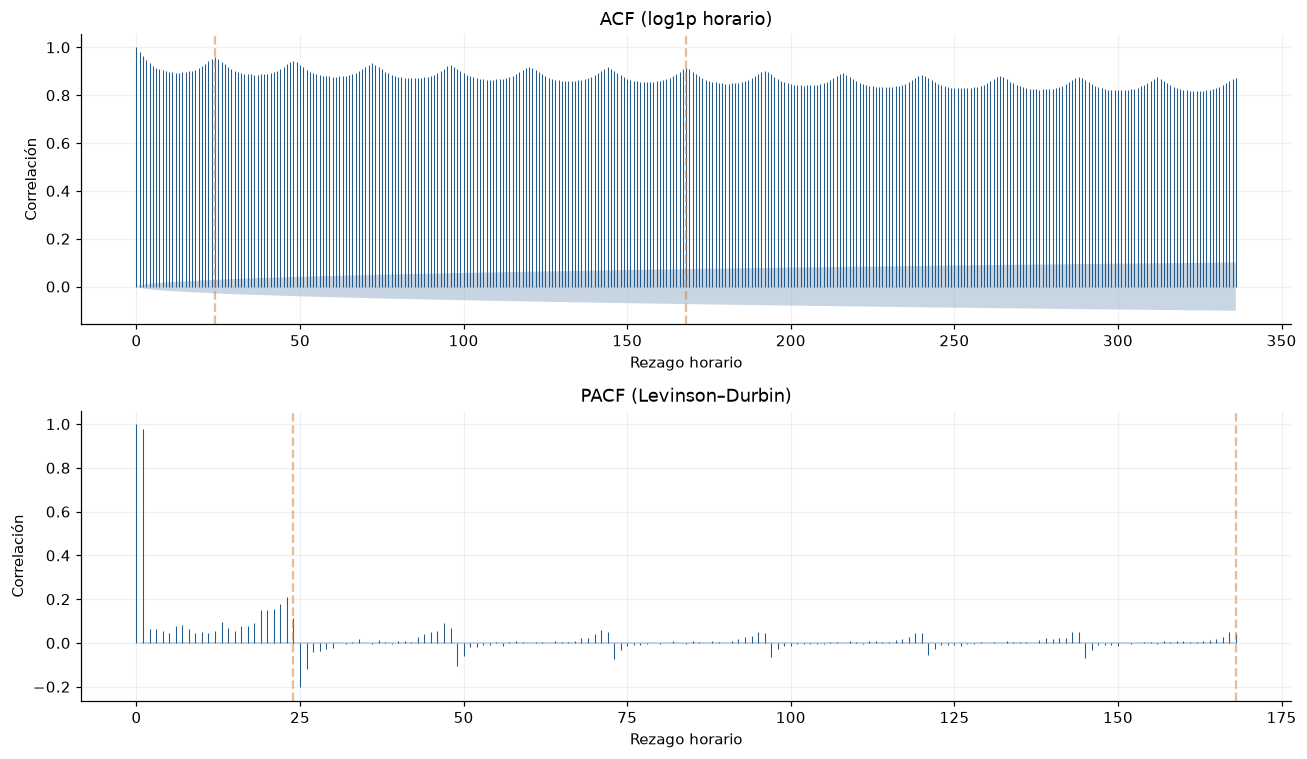

In [13]:
y = np.log1p(frame[TARGET].to_numpy())
ac, ci = acf(y, nlags=336, fft=True, alpha=0.05, result_object=False)
pc, pci = pacf(y, nlags=168, method='ldbiased', alpha=0.05)
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
for ax, vals, bands, title in [(axes[0], ac, ci, 'ACF (log1p horario)'), (axes[1], pc, pci, 'PACF (Levinson–Durbin)')]:
    lags = np.arange(len(vals))
    ax.vlines(lags, 0, vals, lw=0.7)
    ax.fill_between(lags, bands[:, 0] - vals, bands[:, 1] - vals, alpha=0.25)
    for lag in [24, 168]:
        ax.axvline(lag, color='#d17a32', alpha=0.5, ls='--')
    ax.set(xlabel='Rezago horario', ylabel='Correlación', title=title)
figure(fig, 'acf_pacf_desarrollo')

**Interpretación.** La ACF permanece elevada hasta 336 horas y presenta oscilaciones diarias. La PACF concentra su mayor contribución en el primer rezago y muestra estructura alrededor de 24 horas, respaldando una representación con memoria reciente y diaria.

In [14]:
model = AutoReg(np.log1p(daily.to_numpy()), lags=7).fit()
resid = model.resid
arch = het_arch(resid, nlags=14, result_object=False)
bstat, bp = bds(resid[-1000:], max_dim=3, distance=1.5)
diagnostics = pd.DataFrame({'estadístico': [arch[0], *np.atleast_1d(bstat)], 'p': [arch[1], *np.atleast_1d(bp)]}, index=['ARCH LM (14)', 'BDS dimensión 2', 'BDS dimensión 3'])
table(diagnostics, 'dependencia_no_lineal_desarrollo')

,estadístico,p
ARCH LM (14),707.79,5.5953e-142
BDS dimensión 2,10.367,3.4922e-25
BDS dimensión 3,12.008,3.2249e-33


In [15]:
table(acorr_ljungbox(resid, lags=[7, 14, 30], return_df=True), 'ljung_box_ar7_desarrollo')

,lb_stat,lb_pvalue
7,147.29,1.505e-28
14,435.46,4.2031e-84
30,843.86,3.8494e-158


In [16]:
decision('La lectura conjunta ADF/KPSS determina qué transformaciones comparar; no diferenciar automáticamente por un único p-valor.', 'Memoria estacional y varianza variable justifican comparar arquitecturas y pérdidas robustas con referencias lineales fuertes.', 'Errores dependientes requieren bootstrap por bloques o inferencia temporal; las horas y semillas no son observaciones independientes equivalentes.', 'BDS rechaza independencia bajo varias alternativas, incluida heterocedasticidad: no demuestra por sí solo no linealidad de la media ni utilidad del texto. Pruebas exploratorias y sensibles a rupturas.')

### Implicaciones del análisis

- **Preprocesamiento:** La lectura conjunta ADF/KPSS determina qué transformaciones comparar; no diferenciar automáticamente por un único p-valor.
- **Arquitectura:** Memoria estacional y varianza variable justifican comparar arquitecturas y pérdidas robustas con referencias lineales fuertes.
- **Validación:** Errores dependientes requieren bootstrap por bloques o inferencia temporal; las horas y semillas no son observaciones independientes equivalentes.
- **Riesgos:** BDS rechaza independencia bajo varias alternativas, incluida heterocedasticidad: no demuestra por sí solo no linealidad de la media ni utilidad del texto. Pruebas exploratorias y sensibles a rupturas.